In [1]:
import pretty_midi
from pretty_midi.utilities import note_number_to_name, note_name_to_number
import IPython.display as ipd
import numpy as np
import matplotlib.pyplot as plt
import pickle5 as pickle
import json

In [2]:
def midi_to_list(filename, bpm):
    midi_data = pretty_midi.PrettyMIDI(filename)

    midi_list = []

    for instrument in midi_data.instruments:
        for note in instrument.notes:
            start = note.start
            end = note.end
            pitch = note.pitch
            velocity = note.velocity
            midi_list.append([start, end, pitch])

    midi_list = sorted(midi_list, key=lambda x: (x[0], x[2]))

    bps=bpm/60
    steps_per_sec=bps*4
    sixth_step_per_sec=steps_per_sec*6

    c2_midi_note=note_name_to_number("C2")
    note_range=note_name_to_number("C7")-note_name_to_number("C2")

    midi_simple = [(round(x[0]*sixth_step_per_sec), round(x[1]*sixth_step_per_sec)-1, x[2]-c2_midi_note) for x in midi_list]
    return midi_simple, note_range

In [3]:
midi_simple, note_range = midi_to_list(filename = "test_6inch/verse1.mid", bpm=138)

In [4]:
len(midi_simple)

89

In [19]:
def midi_to_grid(filename, bpm):
    midi_simple, note_range = midi_to_list(filename, bpm)
    midi_gridi = np.zeros((note_range, 17*4*4*6))
    
    for x in midi_simple:
        midi_gridi[x[2],x[0]:(x[1]+1)]=1
        midi_gridi[x[2],x[0]]=2

    return midi_gridi

In [22]:
midi_gridi = midi_to_grid(filename = "test_6inch/verse1.mid", bpm=138)

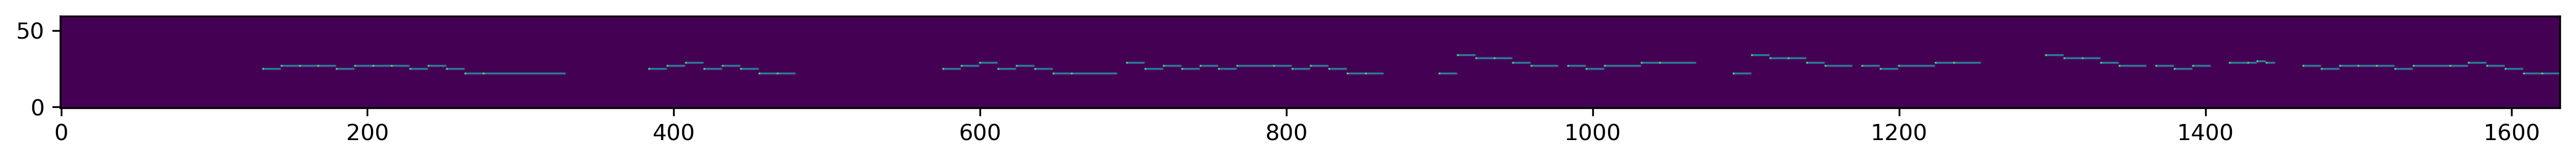

In [23]:
plt.figure(figsize=(20, 20), dpi=300)

plt.imshow(midi_gridi, origin='lower')

In [5]:
def syll_to_json(syll_file, section, midi_file, bpm, out_json_filename):
    stanza = pickle.load( open( syll_file, "rb" ) )[section]
    stanza = stanza.replace('0', '')
    stanza = stanza.replace('1', '')
    stanza = stanza.replace('2', '')
    stanza = stanza.replace('3', '')
    stanza = stanza.replace('4', '')
    stanza = stanza.replace('5', '')
    
    vowels = ["AA", "AE", "AH", "AO", "AW", "AY", "EH", "ER", "EY", "IH", "IY", "OW", "OY", "UH", "UW"]

    consonants = ["B", "CH", "D", "DH", "F", "G", "HH", "JH", "K", "L", "M", "N", "NG", "P", "R", "S", "SH", "T", "TH"
                  , "V", "W", "Y", "Z", "ZH"]
    
    syllables = []

    for line in stanza.split('\r\n'):
        for word in line.split('  '):
    #         print(word)
            vowel_list=[]
            for phoneme in word.split(' '):
                if phoneme in vowels:
                    vowel_list.append(phoneme)
                elif phoneme not in consonants:
                    raise Exception("uh oh weird phoneme")
            if len(vowel_list)==1:
                syllables.append(word)
            else:
                temp_word=word
                for i in range(len(vowel_list)):
                    if i==(len(vowel_list)-2):
                        syllables.append(temp_word.split(vowel_list[i], 1)[0] + vowel_list[i])
                        syllables.append(temp_word.split(vowel_list[i] + " ", 1)[1])
                        break
    #                 print(vowel_list[i])
                    syllables.append(temp_word.split(vowel_list[i], 1)[0] + vowel_list[i])
                    temp_word = temp_word.split(vowel_list[i]+" ", 1)[1]
#     print(len(syllables))
    midi_simple, note_range = midi_to_list(filename = midi_file, bpm=bpm)
    
    temp = ['']*len(midi_simple)
    for i,x in enumerate(syllables):
        temp[i]=x
    temp2 = [(i, x[0],x[1]-x[0],x[2], temp[i]) for i,x in enumerate(midi_simple)]

    data = {}
    data['notes'] = []
    for x in temp2:
        data['notes'].append({
            'id': x[0],
            'start': x[1],
            'duration': x[2],
            'pitch': x[3],
            'syllable': x[4]
        })
    with open(out_json_filename, 'w') as outfile:
        json.dump(data, outfile, indent=4)

In [6]:
syll_to_json(syll_file="test_6inch/BeyoncÇ_6 Inch.pkl"
             , section="verse1"
             , midi_file="test_6inch/verse1.mid"
             , bpm=138,
            out_json_filename='test_6inch/verse1.json')

89


In [117]:
twos = np.asarray(np.where(midi_gridi==2))
twos = twos[:, twos[1,:].argsort()]


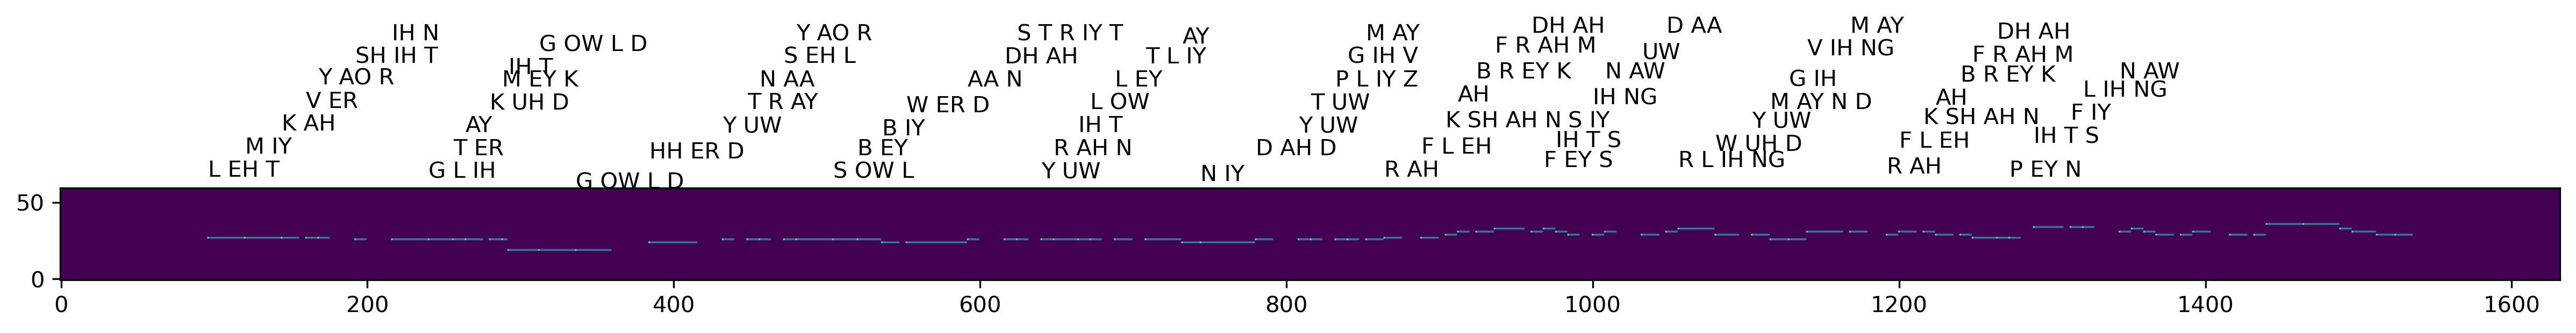

In [130]:
plt.figure(figsize=(20, 20), dpi=300)

offset=[0,15,30,45,60,75,90]
plt.imshow(midi_gridi, origin='lower')
for i,syllable in enumerate(syllables):
    x = twos[0,i]
    y = twos[1,i]
    plt.text(y, x+40+offset[i%7], syllable)